# Amazon ML Challenge 2026 — Business Entity Resolution (V3)

Two-stage pipeline: **scalable IDF-weighted multi-key blocking** → **LightGBM pairwise matcher** →
**macro-F0.5-optimised per-entity decision rule**. Only the provided files are used (no external data or APIs);
the model is LightGBM (MIT licence, a few MB).

### What changed vs V2 (and why it should score higher)
| # | V2 problem | V3 fix |
|---|---|---|
| 1 | Model trained on candidates from a ~230k-record pool, but tested against ~10M records → hard negatives and blocking scores never seen in training (likely cause of the 32.6% empty predictions on test vs 5.6% singletons in training) | Training candidates come from the **full training target pool** with the *identical* blocking code and top-K used at test time |
| 2 | Posting lists truncated to "first N records in file order" (3-grams, street numbers) and popular postal codes dropped entirely → retrieval degrades at scale | Keys above a document-frequency cap are dropped as uninformative; every key is **IDF-weighted**; compound keys (postal+token, postal+number, name+postal) keep common names retrievable |
| 3 | One global probability threshold | Per-entity rule: **gate** on the best candidate (protects singletons) + pair threshold + relative-to-best cut, tuned on macro F0.5 |
| 4 | 20 plain similarity features | 41 features: IDF-weighted token overlap, partial ratio, acronyms, legal-form / digit / postal conflicts, and **candidate-group context** (gap/rank vs the best candidate) |
| 5 | Fixed top-12 candidates | top-K chosen from the recall@k curve plus a per-entity score-ratio cut → **smaller `candidate_pairs.tsv`** at equal recall |
| 6 | 50k-row head slice for training | 300k randomly sampled labelled entities |
| 7 | The same S2/S3 record could be matched to several Source-1 entities | **Target exclusivity**: Source 1 is deduplicated, so each target keeps only its most probable Source-1 entity (auto-enabled after checking the training ground truth) |
| 8 | Stub `run_pipeline.py`, no methodology doc in zip, unseen/empty country rows could be dropped | Real runnable `src/` package + CLI, filled methodology doc, pinned requirements, every Source-1 row guaranteed, official validator executed |

### How to run on Kaggle
1. Attach the challenge dataset, **Settings → Internet ON** (for `pip install rapidfuzz`), accelerator **None (CPU)**.
2. Set `TEAM_NAME` below, then **Save Version → Save & Run All (Commit)** — runs headless, ~3–4 h in total.
3. Download `output/matching_results.tsv` (leaderboard) and `<TEAM_NAME>_submission.zip` (final package) from the Output tab.

In [1]:
%pip install -q rapidfuzz lightgbm
try:
    import rapidfuzz, lightgbm
except ImportError as e:
    raise RuntimeError("rapidfuzz/lightgbm missing: turn on Settings -> Internet in Kaggle and re-run "
                       "(the pure-Python fallback is far too slow for the full test set).") from e
import pandas, numpy
print("rapidfuzz", rapidfuzz.__version__, "| lightgbm", lightgbm.__version__,
      "| pandas", pandas.__version__, "| numpy", numpy.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 30.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
rapidfuzz 3.14.6 | lightgbm 4.6.0 | pandas 2.3.3 | numpy 2.0.2


## Configuration
Paths are auto-detected under `/kaggle/input` (any dataset mirror works). Everything else has sensible defaults.
`REUSE_ARTIFACTS = True` skips training and reloads the saved model — useful if a session dies during test inference.

In [2]:
import os, sys, gc, json, time, importlib, warnings
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)

TEAM_NAME = "Amritians"
N_TRAIN_S1 = 300_000      # labelled Source-1 entities used for training + validation (random sample)
TOP_K = 0                 # 0 = automatic from the recall@k curve; set e.g. 10 to force a smaller candidate set
REUSE_ARTIFACTS = False   # True = load model/rule from artifacts/ instead of training


def find_data_dir(marker: str, env: str):
    if os.environ.get(env):
        return Path(os.environ[env])
    roots = [Path(os.environ["ER_DATA_ROOT"])] if os.environ.get("ER_DATA_ROOT") else (
        [Path("/kaggle/input")] if Path("/kaggle/input").exists() else [Path.cwd()])
    hits = [p.parent for r in roots for p in r.rglob(marker)]
    hits.sort(key=lambda p: ("student_resource" not in str(p), len(str(p))))
    return hits[0] if hits else None


TRAIN_DIR = find_data_dir("train_ground_truth.tsv", "ER_TRAIN_DIR")
TEST_DIR = find_data_dir("test_source1.tsv", "ER_TEST_DIR")
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
os.chdir(WORK_DIR)
SRC_DIR = WORK_DIR / "code" / "business_entity_resolution" / "src"
(SRC_DIR / "er").mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = WORK_DIR / "output"
ARTIFACTS_DIR = WORK_DIR / "artifacts"

print("train dir :", TRAIN_DIR)
print("test dir  :", TEST_DIR)
print("work dir  :", WORK_DIR)
assert TRAIN_DIR is not None and TEST_DIR is not None, "Attach the challenge dataset (train + test folders)."

train dir : /kaggle/input/datasets/nikhileshj/nikhil-dataset/student_resource/dataset/train
test dir  : /kaggle/input/datasets/nikhileshj/nikhil-dataset/student_resource/dataset/test
work dir  : /kaggle/working


## Source modules
Each cell below writes one file of the pipeline package into `code/business_entity_resolution/src/`
(the same files are zipped into the final submission, so the package is exactly what ran here).

In [3]:
%%writefile code/business_entity_resolution/src/er/__init__.py
"""Business entity resolution pipeline (Amazon ML Challenge 2026)."""

Writing code/business_entity_resolution/src/er/__init__.py


### Module 1 — Normalisation of names and addresses (open-set countries, legal forms, abbreviations, transliteration, postal-code extraction).

In [4]:
%%writefile code/business_entity_resolution/src/er/preprocess.py
"""Country-aware (but open-set) normalisation of business names and addresses."""
import re
import sys
import unicodedata
from typing import Dict, List, Tuple

import pandas as pd

LEGAL_FORMS: Dict[str, List[str]] = {
    "US": [
        "limited liability company", "limited liability partnership", "limited partnership",
        "professional corporation", "incorporated", "incorporation", "corporation", "company",
        "limited", "corp", "inc", "llc", "llp", "lp", "ltd", "co", "pllc", "pc", "plc",
    ],
    "India": [
        "private limited company", "private limited", "pvt ltd", "pvt limited", "pvt", "private",
        "limited liability partnership", "public limited company", "public limited", "limited",
        "ltd", "llp", "opc",
    ],
    "France": [
        "societe par actions simplifiee unipersonnelle", "societe par actions simplifiee",
        "societe a responsabilite limitee", "entreprise unipersonnelle a responsabilite limitee",
        "societe anonyme", "societe civile immobiliere", "societe en nom collectif",
        "societe civile", "sasu", "sarl", "sas", "sa", "eurl", "sci", "snc", "gie", "selarl",
        "sca", "scop", "scp",
    ],
}
# Common legal forms of other jurisdictions, used only for countries never seen in training.
OTHER_LEGAL_FORMS = [
    "gmbh", "ag", "kg", "ohg", "ug", "bv", "nv", "vof", "srl", "spa", "sas", "snc", "sl", "slu", "sau",
    "oy", "oyj", "ab", "as", "asa", "aps", "pty ltd", "pty", "pte ltd", "pte", "sdn bhd", "bhd", "kk",
    "sa de cv", "ltda", "eirl", "sp z o o", "sro", "doo", "ad", "plc", "gie",
]
# Unseen countries (open set) get the union of every known legal form.
_ALL_FORMS = sorted({f for forms in LEGAL_FORMS.values() for f in forms} | set(OTHER_LEGAL_FORMS),
                    key=len, reverse=True)

LEGAL_CANON = {
    "ltd": "ltd", "limited": "ltd",
    "pvt ltd": "pvt", "pvt limited": "pvt", "private limited": "pvt", "private limited company": "pvt",
    "pvt": "pvt", "private": "pvt",
    "inc": "inc", "incorporated": "inc", "incorporation": "inc",
    "corp": "corp", "corporation": "corp", "co": "co", "company": "co",
    "llc": "llc", "limited liability company": "llc",
    "llp": "llp", "limited liability partnership": "llp",
    "sarl": "sarl", "societe a responsabilite limitee": "sarl",
    "sas": "sas", "societe par actions simplifiee": "sas",
    "sasu": "sasu", "societe par actions simplifiee unipersonnelle": "sasu",
    "sa": "sa", "societe anonyme": "sa",
    "eurl": "eurl", "entreprise unipersonnelle a responsabilite limitee": "eurl",
    "sci": "sci", "societe civile immobiliere": "sci",
    "snc": "snc", "societe en nom collectif": "snc",
}

NAME_STOPWORDS = {
    "the", "and", "of", "a", "an", "for", "de", "la", "le", "les", "des", "du", "d", "l", "et", "y",
}

NAME_ABBREV = {
    "intl": "international", "mfg": "manufacturing", "mfr": "manufacturers", "mfrs": "manufacturers",
    "svc": "services", "svcs": "services", "srvcs": "services", "service": "services",
    "assoc": "associates", "assocs": "associates", "assn": "association", "bros": "brothers",
    "natl": "national", "univ": "university", "hosp": "hospital", "ctr": "center", "centre": "center",
    "mgmt": "management", "mgt": "management", "sys": "systems", "tech": "technologies",
    "technology": "technologies", "techs": "technologies", "engg": "engineering",
    "pharma": "pharmaceuticals", "pharmaceutical": "pharmaceuticals", "devt": "development",
    "grp": "group", "hldgs": "holdings", "hldg": "holding", "inds": "industries",
    "industry": "industries", "enterprise": "enterprises", "entps": "enterprises",
    "solution": "solutions", "trader": "traders", "mt": "mount", "ft": "fort",
    "sri": "shri", "shree": "shri", "sree": "shri", "cie": "compagnie", "ste": "societe",
}

ADDR_ABBREV = {
    "st": "street", "str": "street", "rd": "road", "ave": "avenue", "av": "avenue", "avn": "avenue",
    "blvd": "boulevard", "bd": "boulevard", "bvd": "boulevard", "dr": "drive", "ln": "lane",
    "ct": "court", "pl": "place", "sq": "square", "hwy": "highway", "pkwy": "parkway",
    "ste": "suite", "fl": "floor", "flr": "floor", "apt": "apartment", "bldg": "building",
    "n": "north", "s": "south", "e": "east", "w": "west", "ne": "northeast", "nw": "northwest",
    "se": "southeast", "sw": "southwest", "nr": "near", "opp": "opposite", "sect": "sector",
    "sec": "sector", "ph": "phase", "mkt": "market", "cir": "circle", "rte": "route",
    "chem": "chemin", "imp": "impasse", "fbg": "faubourg", "stn": "station", "dist": "district",
    "distt": "district", "tq": "taluk", "tal": "taluk", "vill": "village", "vil": "village",
    "blk": "block", "rly": "railway", "ext": "extension", "extn": "extension",
    "pin": "", "zip": "", "cedex": "",
}

POSTAL_PATTERNS = {
    "US": re.compile(r"\b(\d{5})(?:\s\d{4})?\b"),
    "India": re.compile(r"\b(\d{3})\s?(\d{3})\b"),
    "France": re.compile(r"\b(\d{2})\s?(\d{3})\b"),
}
DEFAULT_POSTAL = re.compile(r"\b(\d{4,6})\b")
NULL_VALUES = {"", "none", "null", "nan", "unknown", "n a", "na", "address", "not available", "0"}

_URL = re.compile(r"^\s*(?:https?://)?(?:www\.)?([a-z0-9][a-z0-9\-.]*?)\.(?:com|net|org|in|co|fr|io|biz|info|us|uk)"
                  r"(?:\.[a-z]{2})?/?\s*$", re.IGNORECASE)
_APOS = re.compile(r"['’`´]")
_SINGLE_LETTERS = re.compile(r"\b(?:[a-z0-9] )+[a-z0-9]\b")
_TRANSLIT = str.maketrans({"ß": "ss", "æ": "ae", "Æ": "ae", "œ": "oe", "Œ": "oe", "ø": "o", "Ø": "o",
                           "đ": "d", "Đ": "d", "ł": "l", "Ł": "l", "ı": "i"})
_NONWORD = re.compile(r"[\W_]+")
_DIGITS = re.compile(r"\d+")

_intern = sys.intern


def _alt(forms: List[str]) -> str:
    return "|".join(re.escape(f) for f in sorted(forms, key=len, reverse=True))


# Leading legal forms ("SARL Dupont") are a French convention; only multi-letter forms are
# stripped as prefixes so names like "SA Motors" in other countries are left alone.
_PREFIX_FORMS = [f for f in LEGAL_FORMS["France"] if len(f) >= 3]
_PREFIX_RX = re.compile(rf"^(?:(?:{_alt(_PREFIX_FORMS)})\s)+")
_NO_PREFIX = re.compile(r"(?!x)x")
_LEGAL_RX = {
    c: (re.compile(rf"(?:\s(?:{_alt(f)}))+$"), _PREFIX_RX if c == "France" else _NO_PREFIX)
    for c, f in LEGAL_FORMS.items()
}
_LEGAL_RX_DEFAULT = (re.compile(rf"(?:\s(?:{_alt(_ALL_FORMS)}))+$"), _PREFIX_RX)


def normalize_text(text) -> str:
    """Lower-case, strip accents and punctuation; keeps non-latin letters."""
    if text is None:
        return ""
    s = str(text).strip()
    if not s:
        return ""
    if not s.isascii():
        s = s.translate(_TRANSLIT)
        s = "".join(ch for ch in unicodedata.normalize("NFKD", s) if not unicodedata.combining(ch))
    s = s.lower().replace("&", " and ").replace("@", " at ")
    s = _APOS.sub("", s)
    s = _NONWORD.sub(" ", s)
    return s.strip()


def _strip_legal(name: str, country: str) -> Tuple[str, str]:
    suffix_rx, prefix_rx = _LEGAL_RX.get(country, _LEGAL_RX_DEFAULT)
    form = ""
    m = suffix_rx.search(" " + name)
    if m and m.start() > 0:
        form = m.group(0).strip()
        name = (" " + name)[: m.start()].strip()
    m = prefix_rx.match(name + " ")
    if m and m.end() < len(name) + 1:
        if not form:
            form = m.group(0).strip()
        name = (name + " ")[m.end():].strip()
    if form:
        last = form.split(" ")
        canon = LEGAL_CANON.get(form) or LEGAL_CANON.get(last[-1], form)
        form = canon
    return name, form


def _name_parts(raw_name, country: str):
    raw = "" if raw_name is None else str(raw_name)
    m = _URL.match(raw)
    clean = normalize_text(m.group(1) if m else raw)
    if " " in clean:
        # "S.A." / "L.L.C." / "A B C Traders" -> "sa" / "llc" / "abc traders"
        clean = _SINGLE_LETTERS.sub(lambda x: x.group(0).replace(" ", ""), clean)
    if clean in NULL_VALUES:
        clean = ""
    core, form = _strip_legal(clean, country) if clean else ("", "")
    toks = []
    for t in core.split():
        t = NAME_ABBREV.get(t, t)
        if t and t not in NAME_STOPWORDS:
            toks.append(t)
    if not toks and core:  # name made only of stop-words: keep them
        toks = core.split()
    toks = tuple(_intern(t) for t in dict.fromkeys(toks))
    core_name = " ".join(toks)
    name_key = " ".join(sorted(toks))
    digits = tuple(sorted({d for d in _DIGITS.findall(core_name)}))
    return clean, core_name, toks, name_key, form, digits


def _addr_parts(raw_addr, country: str):
    norm = normalize_text(raw_addr)
    if norm in NULL_VALUES or len(norm) < 3:
        return "", (), "", (), True
    pat = POSTAL_PATTERNS.get(country, DEFAULT_POSTAL)
    postal, span = "", None
    for m in pat.finditer(norm):
        postal, span = "".join(g for g in m.groups() if g), m.span()
    rest = norm if span is None else norm[: span[0]] + " " + norm[span[1]:]
    nums = tuple(dict.fromkeys(_DIGITS.findall(rest)))[:4]
    words = []
    for t in norm.split():
        t = ADDR_ABBREV.get(t, t)
        if t:
            words.append(t)
    clean = " ".join(words)
    toks = tuple(_intern(t) for t in dict.fromkeys(w for w in words if len(w) >= 2 and not w.isdigit()))
    return clean, toks, postal, nums, False


def preprocess_records(df: pd.DataFrame) -> Dict[str, list]:
    """Returns a column store (dict of equal-length lists) for the given source rows."""
    ids = df["entity_id"].astype(str).str.strip().tolist()
    names = df["business_name"].tolist() if "business_name" in df else [""] * len(ids)
    addrs = df["business_address"].tolist() if "business_address" in df else [""] * len(ids)
    countries = (
        df["country"].fillna("").astype(str).str.strip().tolist() if "country" in df else [""] * len(ids)
    )
    cols = {k: [] for k in (
        "name_clean", "name_core", "name_tokens", "name_key", "legal", "name_digits",
        "addr_clean", "addr_tokens", "postal", "nums", "addr_missing",
    )}
    for raw_name, raw_addr, country in zip(names, addrs, countries):
        n_clean, n_core, n_toks, n_key, legal, digits = _name_parts(raw_name, country)
        a_clean, a_toks, postal, nums, missing = _addr_parts(raw_addr, country)
        cols["name_clean"].append(n_clean)
        cols["name_core"].append(n_core)
        cols["name_tokens"].append(n_toks)
        cols["name_key"].append(n_key)
        cols["legal"].append(legal)
        cols["name_digits"].append(digits)
        cols["addr_clean"].append(a_clean)
        cols["addr_tokens"].append(a_toks)
        cols["postal"].append(postal)
        cols["nums"].append(nums)
        cols["addr_missing"].append(missing)
    cols["entity_id"] = ids
    cols["country"] = countries
    return cols


def char_grams(core_name: str, n: int = 3) -> set:
    s = core_name.replace(" ", "")
    if len(s) < n:
        return {s} if s else set()
    return {s[i: i + n] for i in range(len(s) - n + 1)}

Writing code/business_entity_resolution/src/er/preprocess.py


### Module 2 — Candidate generation: IDF-weighted multi-key inverted index with document-frequency caps (scales linearly, bounded work per query).

In [5]:
%%writefile code/business_entity_resolution/src/er/blocking.py
"""Scalable candidate generation: IDF-weighted inverted index over several blocking keys.

Every key type has a document-frequency cap. Keys whose posting list exceeds the cap are
dropped entirely (they are too common to be discriminative), so posting lists are never
silently truncated to "the first N records in file order". Compound keys (postal+token,
postal+street number, full name+postal) keep common names retrievable when they share a
locality. A locality fallback key ("L"/"NL") activates when postal-code parsing fails
(e.g. missing PIN codes, landmark-based addresses), keying on the trailing address token
instead of losing all location signal. Work per query is bounded by sum(caps), independent
of the corpus size.
"""
import heapq
import math
from operator import itemgetter
from typing import Dict, List, Tuple

from .preprocess import char_grams

# Caps raised ~2.5-4x from the initial pass: at 4-6M records per country, common-but-real
# tokens/grams routinely exceeded the old caps and were dropped outright (score 0, never
# retrieved) rather than down-weighted by IDF. Raising the cap lets IDF weighting do its job
# instead of the key vanishing. Query cost scales with sum(caps), so this roughly triples
# per-query work in exchange for closing most of the "zero shared key" recall gap measured
# via the recall@k curve (which was already flat by k=20, indicating a missing-key problem,
# not a ranking problem).
KEY_CAPS = {"T": 6000, "G": 3000, "N": 2500, "P": 5000, "S": 1200, "A": 3000,
            "PT": 1200, "PS": 1000, "NP": 500, "L": 4000, "NL": 600}
KEY_WEIGHTS = {"T": 3.0, "G": 0.35, "N": 4.0, "P": 1.5, "S": 1.0, "A": 0.8,
               "PT": 3.0, "PS": 2.5, "NP": 5.0, "L": 0.6, "NL": 4.0}


def record_keys(name_tokens, name_core, name_key, postal, nums, addr_tokens) -> List[Tuple[str, tuple]]:
    keys = [
        ("T", name_tokens),
        ("G", tuple(char_grams(name_core))),
        ("N", (name_key,) if name_key else ()),
        ("A", addr_tokens),
        ("S", nums),
    ]
    if postal:
        keys.append(("P", (postal,)))
        keys.append(("PT", tuple(postal + "|" + t for t in name_tokens)))
        keys.append(("PS", tuple(postal + "|" + n for n in nums)))
        if name_key:
            keys.append(("NP", (name_key + "|" + postal,)))
    else:
        # No postal code parsed - common when PIN/ZIP is missing or the address is
        # landmark-based. Fall back to a coarse locality signal from the trailing address
        # token (often the city/area name), so records can still be linked by approximate
        # location instead of losing all address-side signal.
        if addr_tokens:
            locality = addr_tokens[-1]
            keys.append(("L", (locality,)))
            if name_key:
                keys.append(("NL", (name_key + "|" + locality,)))
    return keys


def keys_for_table(tbl: Dict[str, list], i: int):
    return record_keys(tbl["name_tokens"][i], tbl["name_core"][i], tbl["name_key"][i],
                       tbl["postal"][i], tbl["nums"][i], tbl["addr_tokens"][i])


class BlockingIndex:
    def __init__(self, caps: Dict[str, int] = None, weights: Dict[str, float] = None) -> None:
        self.caps = dict(caps or KEY_CAPS)
        self.weights = dict(weights or KEY_WEIGHTS)
        self.tables: Dict[str, Dict[str, list]] = {t: {} for t in self.caps}
        self.wtabs: Dict[str, List[float]] = {}
        self.n_records = 0

    def build(self, tbl: Dict[str, list]) -> "BlockingIndex":
        n = len(tbl["entity_id"])
        tables, caps = self.tables, self.caps
        over = {t: set() for t in caps}
        for i in range(n):
            for t, vals in keys_for_table(tbl, i):
                table, cap = tables[t], caps[t]
                for v in vals:
                    lst = table.get(v)
                    if lst is None:
                        table[v] = [i]
                    elif len(lst) < cap:
                        lst.append(i)
                    else:
                        over[t].add(v)
        for t, keys in over.items():
            table = tables[t]
            for v in keys:
                del table[v]
        self.n_records = n
        log_n = math.log(n + 1.0)
        for t, cap in caps.items():
            w = self.weights[t]
            # idf normalised to (0, 1]: rare keys count fully, near-cap keys count little
            self.wtabs[t] = [0.0] + [w * math.log((n + 1.0) / df) / log_n for df in range(1, cap + 1)]
        return self

    def query(self, keys, k: int) -> List[Tuple[int, float]]:
        scores: Dict[int, float] = {}
        get = scores.get
        tables, wtabs = self.tables, self.wtabs
        for t, vals in keys:
            table, wtab = tables[t], wtabs[t]
            for v in vals:
                lst = table.get(v)
                if lst is None:
                    continue
                w = wtab[len(lst)]
                for c in lst:
                    scores[c] = get(c, 0.0) + w
        if not scores:
            return []
        return heapq.nlargest(k, scores.items(), key=itemgetter(1))

    def stats(self) -> Dict[str, int]:
        return {t: len(tbl) for t, tbl in self.tables.items()}


Writing code/business_entity_resolution/src/er/blocking.py


### Module 3 — 34 pairwise features (RapidFuzz batched in C++) + 7 candidate-group context features.

In [6]:
%%writefile code/business_entity_resolution/src/er/features.py
"""Pairwise + candidate-group context features (all country-agnostic, so they transfer to France)."""
import math
from collections import Counter
from itertools import chain
from typing import Dict

import numpy as np
import pandas as pd

from .preprocess import char_grams

try:
    from rapidfuzz import fuzz
    from rapidfuzz.distance import JaroWinkler

    try:
        from rapidfuzz.process import cpdist
    except ImportError:  # rapidfuzz < 3.6
        cpdist = None
    SCORERS = {"ratio": fuzz.ratio, "token_sort": fuzz.token_sort_ratio, "token_set": fuzz.token_set_ratio,
               "partial": fuzz.partial_ratio, "jw": JaroWinkler.normalized_similarity}
    SCALE = {"ratio": 100.0, "token_sort": 100.0, "token_set": 100.0, "partial": 100.0, "jw": 1.0}
except ImportError:  # pure-python fallback, slower but same outputs in [0, 1]
    import difflib

    cpdist = None

    def _r(a, b):
        return difflib.SequenceMatcher(None, a, b).ratio()

    def _tsort(a, b):
        return _r(" ".join(sorted(a.split())), " ".join(sorted(b.split())))

    def _tset(a, b):
        sa, sb = set(a.split()), set(b.split())
        inter = " ".join(sorted(sa & sb))
        da = (inter + " " + " ".join(sorted(sa - sb))).strip()
        db = (inter + " " + " ".join(sorted(sb - sa))).strip()
        return max(_r(inter, da), _r(inter, db), _r(da, db))

    def _partial(a, b):
        short, long_ = (a, b) if len(a) <= len(b) else (b, a)
        m = difflib.SequenceMatcher(None, short, long_).find_longest_match(0, len(short), 0, len(long_))
        return m.size / max(1, len(short))

    SCORERS = {"ratio": _r, "token_sort": _tsort, "token_set": _tset, "partial": _partial, "jw": _r}
    SCALE = {k: 1.0 for k in SCORERS}


BASE_FEATURES = [
    "name_ratio", "core_ratio", "core_token_sort", "core_token_set", "core_partial", "core_jw",
    "gram_jaccard", "core_exact", "namekey_exact", "core_len_ratio",
    "tok_idf_jaccard", "tok_idf_cov_s1", "tok_idf_cov_t", "shared_tok_count", "max_shared_idf",
    "max_missing_idf", "first_tok_equal", "acronym_match", "legal_cmp", "name_digits_cmp",
    "addr_ratio", "addr_token_sort", "addr_token_set", "addr_idf_jaccard", "num_overlap",
    "num_conflict", "postal_cmp", "s1_addr_missing", "t_addr_missing", "is_s3",
    "bscore", "brank", "bscore_ratio", "name_empty",
]
CONTEXT_FEATURES = [
    "group_size", "core_token_set_gap", "core_token_set_rank", "tok_idf_jaccard_gap",
    "tok_idf_jaccard_rank", "addr_token_set_gap", "n_strong_in_group",
]
FEATURE_NAMES = BASE_FEATURES + CONTEXT_FEATURES


class IdfTable(dict):
    """token -> IDF normalised to [0, 1] on one country's target pool (memoised on first use)."""

    def __init__(self, token_lists, n_docs: int) -> None:
        super().__init__()
        self.df = Counter(chain.from_iterable(token_lists))
        self.n1 = n_docs + 1.0
        self.log_n1 = math.log(self.n1) if n_docs > 0 else 1.0

    def __missing__(self, tok: str) -> float:
        v = math.log(self.n1 / (self.df.get(tok, 0) + 1.0)) / self.log_n1
        v = 1.0 if v > 1.0 else (0.0 if v < 0.0 else v)
        self[tok] = v
        return v


def _bulk(name: str, a: list, b: list) -> np.ndarray:
    scorer = SCORERS[name]
    if cpdist is not None and len(a):
        out = cpdist(a, b, scorer=scorer, workers=-1, dtype=np.float32)
    else:
        out = np.fromiter((scorer(x, y) for x, y in zip(a, b)), dtype=np.float32, count=len(a))
    return out / np.float32(SCALE[name])


def _acronym(toks) -> str:
    return "".join(t[0] for t in toks) if len(toks) >= 2 else ""


def pair_features(s1: Dict[str, list], tg: Dict[str, list], s1_idx, t_idx, bscore, brank, bmax,
                  name_idf: IdfTable, addr_idf: IdfTable) -> np.ndarray:
    si, ti = np.asarray(s1_idx).tolist(), np.asarray(t_idx).tolist()
    n = len(si)
    out = np.zeros((n, len(BASE_FEATURES)), dtype=np.float32)
    if n == 0:
        return out
    S, T = s1, tg
    a_core = [S["name_core"][i] for i in si]
    b_core = [T["name_core"][j] for j in ti]
    a_addr = [S["addr_clean"][i] for i in si]
    b_addr = [T["addr_clean"][j] for j in ti]
    a_miss = np.fromiter((S["addr_missing"][i] for i in si), dtype=bool, count=n)
    b_miss = np.fromiter((T["addr_missing"][j] for j in ti), dtype=bool, count=n)
    has_name = np.fromiter((bool(x) and bool(y) for x, y in zip(a_core, b_core)), dtype=bool, count=n)
    has_addr = ~a_miss & ~b_miss

    out[:, 0] = _bulk("ratio", [S["name_clean"][i] for i in si], [T["name_clean"][j] for j in ti])
    out[:, 1] = _bulk("ratio", a_core, b_core)
    out[:, 2] = _bulk("token_sort", a_core, b_core)
    out[:, 3] = _bulk("token_set", a_core, b_core)
    out[:, 4] = _bulk("partial", a_core, b_core)
    out[:, 5] = _bulk("jw", a_core, b_core)
    out[:, 20] = _bulk("ratio", a_addr, b_addr)
    out[:, 21] = _bulk("token_sort", a_addr, b_addr)
    out[:, 22] = _bulk("token_set", a_addr, b_addr)
    out[~has_name, 0:6] = 0.0
    out[~has_addr, 20:23] = 0.0

    S_toks, T_toks, S_key, T_key = S["name_tokens"], T["name_tokens"], S["name_key"], T["name_key"]
    S_legal, T_legal, S_dig, T_dig = S["legal"], T["legal"], S["name_digits"], T["name_digits"]
    S_atoks, T_atoks, S_post, T_post = S["addr_tokens"], T["addr_tokens"], S["postal"], T["postal"]
    S_nums, T_nums, T_id = S["nums"], T["nums"], T["entity_id"]
    nidf, aidf = name_idf.__getitem__, addr_idf.__getitem__

    grams_cache: Dict[str, frozenset] = {}

    def grams(s):
        g = grams_cache.get(s)
        if g is None:
            g = frozenset(char_grams(s))
            grams_cache[s] = g
        return g

    cols = [[] for _ in range(12)]
    (c_gram, c_exact, c_key, c_len, c_jac, c_cov_a, c_cov_b, c_nshared, c_maxsh, c_maxmiss,
     c_first, c_acr) = cols
    c_addr_jac = []
    rest = []  # legal, digits, num_overlap, num_conflict, postal, is_s3
    for r in range(n):
        i, j = si[r], ti[r]
        ac, bc = a_core[r], b_core[r]
        if ac and bc:
            ga, gb = grams(ac), grams(bc)
            inter = len(ga & gb)
            c_gram.append(inter / (len(ga) + len(gb) - inter) if ga and gb else 0.0)
            c_exact.append(1.0 if ac == bc else 0.0)
            c_key.append(1.0 if S_key[i] == T_key[j] else 0.0)
            la, lb = len(ac), len(bc)
            c_len.append(la / lb if la < lb else lb / la)
            ta, tb = S_toks[i], T_toks[j]
            sa, sb = set(ta), set(tb)
            shared = sa & sb
            w_a = sum(map(nidf, sa))
            w_b = sum(map(nidf, sb))
            if shared:
                w_sh = sum(map(nidf, shared))
                c_maxsh.append(max(map(nidf, shared)))
            else:
                w_sh = 0.0
                c_maxsh.append(0.0)
            diff = sa ^ sb
            c_maxmiss.append(max(map(nidf, diff)) if diff else 0.0)
            w_un = w_a + w_b - w_sh
            c_jac.append(w_sh / w_un if w_un > 0 else 0.0)
            c_cov_a.append(w_sh / w_a if w_a > 0 else 0.0)
            c_cov_b.append(w_sh / w_b if w_b > 0 else 0.0)
            c_nshared.append(float(len(shared)))
            c_first.append(1.0 if ta and tb and ta[0] == tb[0] else 0.0)
            acr_a, acr_b = _acronym(ta), _acronym(tb)
            c_acr.append(1.0 if ((acr_a and (acr_a in sb or acr_a == bc.replace(" ", "")))
                                 or (acr_b and (acr_b in sa or acr_b == ac.replace(" ", "")))) else 0.0)
        else:
            for c in cols:
                c.append(0.0)
        if has_addr[r]:
            xa, xb = set(S_atoks[i]), set(T_atoks[j])
            if xa and xb:
                sh = xa & xb
                w_sh = sum(map(aidf, sh)) if sh else 0.0
                w_un = sum(map(aidf, xa)) + sum(map(aidf, xb)) - w_sh
                c_addr_jac.append(w_sh / w_un if w_un > 0 else 0.0)
            else:
                c_addr_jac.append(0.0)
        else:
            c_addr_jac.append(0.0)
        la_, lb_ = S_legal[i], T_legal[j]
        legal = 0.0 if not (la_ and lb_) else (1.0 if la_ == lb_ else -1.0)
        da, db = S_dig[i], T_dig[j]
        digits = 0.0 if not (da and db) else (1.0 if set(da) & set(db) else -1.0)
        na, nb = S_nums[i], T_nums[j]
        if na and nb:
            ov = float(len(set(na) & set(nb)))
            conflict = 1.0 if ov == 0 else 0.0
        else:
            ov, conflict = 0.0, 0.0
        pa, pb = S_post[i], T_post[j]
        postal = 0.0 if not (pa and pb) else (1.0 if pa == pb else (0.5 if pa[:3] == pb[:3] else -1.0))
        rest.append((legal, digits, ov, conflict, postal, 1.0 if T_id[j].startswith("S3") else 0.0))

    for col, idx in zip(cols, (6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17)):
        out[:, idx] = col
    out[:, 23] = c_addr_jac
    rest_arr = np.asarray(rest, dtype=np.float32)
    out[:, 18] = rest_arr[:, 0]
    out[:, 19] = rest_arr[:, 1]
    out[:, 24] = rest_arr[:, 2]
    out[:, 25] = rest_arr[:, 3]
    out[:, 26] = rest_arr[:, 4]
    out[:, 29] = rest_arr[:, 5]
    out[:, 27] = a_miss
    out[:, 28] = b_miss
    out[:, 30] = bscore
    out[:, 31] = brank
    out[:, 32] = np.asarray(bscore, dtype=np.float32) / np.maximum(np.asarray(bmax, dtype=np.float32), 1e-6)
    out[:, 33] = ~has_name
    return out


def add_context_features(base: np.ndarray, group: np.ndarray) -> pd.DataFrame:
    """Compares every candidate with the other candidates of the same Source-1 entity."""
    df = pd.DataFrame(base, columns=BASE_FEATURES)
    g = pd.Series(group)
    df["group_size"] = g.map(g.value_counts()).to_numpy(dtype=np.float32)
    for col, gap_name, rank_name in (
        ("core_token_set", "core_token_set_gap", "core_token_set_rank"),
        ("tok_idf_jaccard", "tok_idf_jaccard_gap", "tok_idf_jaccard_rank"),
        ("addr_token_set", "addr_token_set_gap", None),
    ):
        grp = df[col].groupby(group)
        df[gap_name] = (df[col] - grp.transform("max")).astype(np.float32)
        if rank_name:
            df[rank_name] = grp.rank(method="min", ascending=False).astype(np.float32)
    strong = (df["core_token_set"] >= 0.9).astype(np.float32)
    df["n_strong_in_group"] = strong.groupby(group).transform("sum").astype(np.float32)
    return df[FEATURE_NAMES]

Writing code/business_entity_resolution/src/er/features.py


### Module 4 — LightGBM matcher with early stopping.

In [7]:
%%writefile code/business_entity_resolution/src/er/model.py
"""Gradient-boosted pairwise matcher (LightGBM, MIT licence; a few MB, far below the 8B limit)."""
import pickle
from pathlib import Path
from typing import List, Optional

import numpy as np
import pandas as pd

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

LGB_PARAMS = {
    "objective": "binary",
    "learning_rate": 0.05,
    "num_leaves": 63,
    "min_data_in_leaf": 40,
    "feature_fraction": 0.85,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 1.0,
    "max_bin": 255,
    "seed": 42,
    "deterministic": True,
    "force_row_wise": True,
    "verbose": -1,
}


class MatchModel:
    def __init__(self, params: Optional[dict] = None, num_boost_round: int = 4000, early_stopping: int = 150):
        self.params = dict(LGB_PARAMS, **(params or {}))
        self.num_boost_round = num_boost_round
        self.early_stopping = early_stopping
        self.feature_names: List[str] = []
        self.booster = None
        self.sk_model = None
        self.best_iteration = 0

    def fit(self, X_tr: pd.DataFrame, y_tr, X_va: pd.DataFrame, y_va) -> "MatchModel":
        self.feature_names = list(X_tr.columns)
        y_tr = np.asarray(y_tr, dtype=np.float32)
        y_va = np.asarray(y_va, dtype=np.float32)
        if HAS_LGB:
            dtr = lgb.Dataset(X_tr.to_numpy(np.float32), label=y_tr, feature_name=self.feature_names, free_raw_data=True)
            dva = lgb.Dataset(X_va.to_numpy(np.float32), label=y_va, reference=dtr, free_raw_data=True)
            self.booster = lgb.train(
                self.params, dtr, num_boost_round=self.num_boost_round, valid_sets=[dva], valid_names=["val"],
                callbacks=[lgb.early_stopping(self.early_stopping, verbose=False), lgb.log_evaluation(250)],
            )
            self.best_iteration = self.booster.best_iteration or self.booster.current_iteration()
        else:
            from sklearn.ensemble import HistGradientBoostingClassifier
            self.sk_model = HistGradientBoostingClassifier(
                max_iter=1500, learning_rate=0.05, max_leaf_nodes=63, early_stopping=True,
                validation_fraction=0.1, random_state=42)
            self.sk_model.fit(X_tr.to_numpy(np.float32), y_tr)
            self.best_iteration = self.sk_model.n_iter_
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        if len(X) == 0:
            return np.zeros(0, dtype=np.float64)
        arr = X[self.feature_names].to_numpy(np.float32)
        if self.booster is not None:
            return self.booster.predict(arr, num_iteration=self.best_iteration)
        return self.sk_model.predict_proba(arr)[:, 1]

    def feature_importance(self) -> pd.DataFrame:
        if self.booster is not None:
            imp = self.booster.feature_importance(importance_type="gain")
        else:
            imp = np.zeros(len(self.feature_names))
        return (pd.DataFrame({"feature": self.feature_names, "gain": imp})
                .sort_values("gain", ascending=False).reset_index(drop=True))

    def save(self, path) -> None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        with open(path, "wb") as f:
            pickle.dump(self, f)

    @staticmethod
    def load(path) -> "MatchModel":
        with open(path, "rb") as f:
            return pickle.load(f)

Writing code/business_entity_resolution/src/er/model.py


### Module 5 — Official macro F0.5 metric and the gate / pair / relative decision rule tuned on it.

In [8]:
%%writefile code/business_entity_resolution/src/er/decision.py
"""Official macro F0.5 metric and the three-parameter decision rule tuned against it.

Rule for one Source-1 entity with candidate probabilities p (max = p1):
    if p1 < gate:                       predict nothing (singleton protection)
    else keep candidates with p >= pair and p >= rel * p1, plus always the top candidate.
"""
import itertools
from typing import Dict, Tuple

import numpy as np
import pandas as pd


def group_max(ent: np.ndarray, p: np.ndarray) -> np.ndarray:
    return pd.Series(p).groupby(ent).transform("max").to_numpy()


def select(p: np.ndarray, pmax: np.ndarray, gate: float, pair: float, rel: float) -> np.ndarray:
    return (pmax >= gate) & (((p >= pair) & (p >= rel * pmax)) | (p >= pmax))


def entity_scores(ent: np.ndarray, label: np.ndarray, sel: np.ndarray, n_true: np.ndarray):
    """Per-entity (f05, precision, recall) exactly as the competition defines them."""
    n_ent = len(n_true)
    npred = np.bincount(ent, weights=sel, minlength=n_ent)
    tp = np.bincount(ent, weights=sel & label, minlength=n_ent)
    f = np.zeros(n_ent)
    prec = np.zeros(n_ent)
    rec = np.zeros(n_ent)
    single = n_true == 0
    f[single] = (npred[single] == 0).astype(float)
    prec[single] = f[single]
    rec[single] = 1.0
    m = ~single & (npred > 0)
    p_ = tp[m] / npred[m]
    r_ = tp[m] / n_true[m]
    den = 0.25 * p_ + r_
    f[m] = np.where(den > 0, 1.25 * p_ * r_ / np.where(den > 0, den, 1), 0.0)
    prec[m], rec[m] = p_, r_
    return f, prec, rec


def summarize(ent, label, sel, n_true) -> Dict[str, float]:
    f, prec, rec = entity_scores(ent, label, sel, n_true)
    single = n_true == 0
    return {
        "macro_f05": float(f.mean()),
        "macro_precision": float(prec.mean()),
        "macro_recall": float(rec.mean()),
        "singleton_accuracy": float(f[single].mean()) if single.any() else 1.0,
        "singleton_count": int(single.sum()),
        "matched_entity_f05": float(f[~single].mean()) if (~single).any() else 0.0,
    }


def tune_rule(ent: np.ndarray, p: np.ndarray, label: np.ndarray, n_true: np.ndarray):
    """Coarse-to-fine grid search of (gate, pair, rel) maximising macro F0.5."""
    label = label.astype(bool)
    pmax = group_max(ent, p)

    def score(g, q, r):
        return entity_scores(ent, label, select(p, pmax, g, q, r), n_true)[0].mean()

    rels = [0.0, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9]
    best = (-1.0, 0.5, 0.5, 0.0)
    for g, q, r in itertools.product(np.arange(0.20, 0.96, 0.05), np.arange(0.10, 0.96, 0.05), rels):
        s = score(g, q, r)
        if s > best[0]:
            best = (s, g, q, r)
    _, g0, q0, r0 = best
    for g, q in itertools.product(np.arange(max(0.05, g0 - 0.05), min(0.99, g0 + 0.051), 0.01),
                                  np.arange(max(0.05, q0 - 0.05), min(0.99, q0 + 0.051), 0.01)):
        s = score(g, q, r0)
        if s > best[0]:
            best = (s, g, q, r0)
    _, g0, q0, _ = best
    for r in np.arange(max(0.0, r0 - 0.15), min(0.99, r0 + 0.151), 0.05):
        s = score(g0, q0, r)
        if s > best[0]:
            best = (s, g0, q0, r)
    _, g, q, r = best
    rule = {"gate": round(float(g), 4), "pair": round(float(q), 4), "rel": round(float(r), 4)}

    # single-threshold curve (the v1/v2 rule) for comparison and plotting
    curve = []
    for t in np.arange(0.10, 0.96, 0.02):
        sel = select(p, pmax, t, t, 0.0)
        m = summarize(ent, label, sel, n_true)
        m["threshold"] = round(float(t), 3)
        curve.append(m)
    return rule, pd.DataFrame(curve)


def apply_rule(ent: np.ndarray, p: np.ndarray, rule: Dict[str, float]) -> np.ndarray:
    return select(p, group_max(ent, p), rule["gate"], rule["pair"], rule["rel"])


def enforce_exclusive(target_key: np.ndarray, p: np.ndarray, sel: np.ndarray) -> np.ndarray:
    """Source 1 is deduplicated, so a target record can belong to at most one Source-1 entity:
    among selected pairs sharing a target, keep only the most probable one."""
    idx = np.flatnonzero(sel)
    if len(idx) == 0:
        return sel
    df = pd.DataFrame({"t": target_key[idx], "p": p[idx], "i": idx})
    keep = (df.sort_values("p", ascending=False, kind="mergesort")
            .drop_duplicates("t", keep="first")["i"].to_numpy())
    out = np.zeros_like(sel)
    out[keep] = True
    return out

Writing code/business_entity_resolution/src/er/decision.py


### Module 6 — TSV loading (tab separated, all columns as strings).

In [9]:
%%writefile code/business_entity_resolution/src/er/data.py
"""TSV loading helpers (tab separated, every column read as string, empty fields kept as '')."""
from pathlib import Path
from typing import Dict, Set

import pandas as pd

SRC_COLS = ["entity_id", "business_name", "business_address", "country"]


def read_source(path) -> pd.DataFrame:
    df = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, na_filter=False)
    df.columns = [str(c).strip().lower() for c in df.columns]
    for c in SRC_COLS:
        if c not in df.columns:
            df[c] = ""
    df = df[SRC_COLS].copy()
    df["entity_id"] = df["entity_id"].str.strip()
    df["country"] = df["country"].str.strip()
    return df[df["entity_id"] != ""]


def read_targets(data_dir, split: str) -> pd.DataFrame:
    parts = [read_source(Path(data_dir) / f"{split}_source{k}.tsv") for k in (2, 3)]
    return pd.concat(parts, ignore_index=True).drop_duplicates("entity_id", keep="first")


def partition_by_country(df: pd.DataFrame) -> Dict[str, pd.DataFrame]:
    return {c: g.reset_index(drop=True) for c, g in df.groupby("country", sort=True)}


def read_ground_truth(path) -> Dict[str, Set[str]]:
    df = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, na_filter=False)
    df.columns = [str(c).strip().lower() for c in df.columns]
    gt: Dict[str, Set[str]] = {}
    for s1, raw in zip(df["source1_entity_id"], df["matched_entity_ids"]):
        s1 = s1.strip()
        raw = raw.strip()
        gt[s1] = {x.strip() for x in raw.split(",") if x.strip()} if raw and raw.lower() != "nan" else set()
    return gt

Writing code/business_entity_resolution/src/er/data.py


### Module 7 — Orchestration: realistic training set, top-K / α selection, training, streaming test inference.

In [10]:
%%writefile code/business_entity_resolution/src/er/pipeline.py
"""End-to-end orchestration: realistic training set, model fitting, rule tuning, streaming test inference.

Training candidates are retrieved from the FULL training target pool of each country with exactly
the same blocking code and top-K used at test time, so the matcher learns on the hard negatives
and blocking-score distributions it will meet on the 10M-record test pool.
"""
import gc
import json
import time
from dataclasses import asdict, dataclass
from collections import Counter
from pathlib import Path
from typing import Dict

import numpy as np
import pandas as pd

from .blocking import BlockingIndex, keys_for_table
from .data import partition_by_country, read_ground_truth, read_source, read_targets
from .decision import apply_rule, enforce_exclusive, entity_scores, summarize, tune_rule
from .features import BASE_FEATURES, IdfTable, add_context_features, pair_features
from .model import MatchModel
from .preprocess import preprocess_records


@dataclass
class Config:
    train_dir: str
    test_dir: str
    output_dir: str = "output"
    artifacts_dir: str = "artifacts"
    n_train_s1: int = 300_000   # labelled Source-1 entities sampled (randomly) for training/validation
    k_max: int = 20             # candidates retrieved while measuring recall@k on training data
    top_k: int = 0              # 0 = choose automatically from the recall@k curve
    recall_keep: float = 0.98   # auto top_k keeps >= this share of recall@k_max
    min_top_k: int = 5
    score_ratio_min: float = -1.0   # <0 = auto: drop candidates scoring below alpha * best candidate
    alpha_max_recall_loss: float = 0.003  # relative recall the auto alpha may give up
    exclusive_targets: str = "auto"  # auto = on if ground truth shows each target has <=1 Source-1 match
    val_frac: float = 0.2
    seed: int = 42
    s1_chunk: int = 20_000


def log(msg: str) -> None:
    print(msg, flush=True)


class CountryContext:
    """Preprocessed target pool, IDF tables and blocking index for one country."""

    def __init__(self, country: str, target_df: pd.DataFrame) -> None:
        t0 = time.time()
        self.country = country
        self.tbl = preprocess_records(target_df)
        n = len(self.tbl["entity_id"])
        self.name_idf = IdfTable(self.tbl["name_tokens"], n)
        self.addr_idf = IdfTable(self.tbl["addr_tokens"], n)
        self.index = BlockingIndex().build(self.tbl)
        log(f"[{country}] target pool ready: {n:,} records, "
            f"{sum(self.index.stats().values()):,} blocking keys ({time.time() - t0:.0f}s)")

    def retrieve(self, s1_tbl: Dict[str, list], k: int, log_every: int = 0, alpha: float = 0.0):
        si, ti, sc, rk, mx = [], [], [], [], []
        n = len(s1_tbl["entity_id"])
        t0 = time.time()
        for i in range(n):
            cands = self.index.query(keys_for_table(s1_tbl, i), k)
            if cands:
                top = cands[0][1]
                floor = alpha * top
                for r, (j, s) in enumerate(cands, 1):
                    if s < floor:
                        break
                    si.append(i)
                    ti.append(j)
                    sc.append(s)
                    rk.append(r)
                    mx.append(top)
            if log_every and (i + 1) % log_every == 0:
                log(f"[{self.country}] blocking {i + 1:,}/{n:,} ({(i + 1) / (time.time() - t0):.0f} entities/s)")
        return (np.asarray(si, np.int64), np.asarray(ti, np.int64), np.asarray(sc, np.float32),
                np.asarray(rk, np.float32), np.asarray(mx, np.float32))

    def features(self, s1_tbl, si, ti, sc, rk, mx) -> np.ndarray:
        return pair_features(s1_tbl, self.tbl, si, ti, sc, rk, mx, self.name_idf, self.addr_idf)


# --------------------------------------------------------------------------------------------
# Training
# --------------------------------------------------------------------------------------------
def prepare_training(cfg: Config) -> dict:
    t_start = time.time()
    train_dir = Path(cfg.train_dir)
    gt = read_ground_truth(train_dir / "train_ground_truth.tsv")
    t_count = Counter(t for v in gt.values() for t in v)
    multi_rate = sum(1 for c in t_count.values() if c > 1) / max(1, len(t_count))
    log(f"Ground truth: {len(gt):,} Source-1 rows; {len(t_count):,} distinct matched targets, "
        f"{multi_rate:.4%} of them matched to more than one Source-1 entity")
    del t_count
    s1_all = read_source(train_dir / "train_source1.tsv")
    s1_all = s1_all[s1_all["entity_id"].isin(gt.keys())].drop_duplicates("entity_id")
    ids = s1_all["entity_id"].to_numpy()
    if cfg.n_train_s1 and len(ids) > cfg.n_train_s1:
        ids = np.random.default_rng(cfg.seed).choice(ids, cfg.n_train_s1, replace=False)
    s1 = s1_all[s1_all["entity_id"].isin(set(ids))].reset_index(drop=True)
    del s1_all
    n_true = np.array([len(gt[e]) for e in s1["entity_id"]], dtype=np.float64)
    log(f"Training entities: {len(s1):,} sampled "
        f"({int((n_true == 0).sum()):,} singletons, {int(n_true.sum()):,} true links, "
        f"countries: {s1['country'].value_counts().to_dict()})")

    targets = read_targets(train_dir, "train")
    log(f"Training target pool (S2+S3): {len(targets):,} records, "
        f"countries: {targets['country'].value_counts().to_dict()}")

    # Diagnostic: true links whose target lives in a different country partition are unreachable.
    t_country = pd.Series(targets["country"].to_numpy(), index=targets["entity_id"].to_numpy())
    link_s1c, link_t = [], []
    for e, c in zip(s1["entity_id"], s1["country"]):
        for t in gt[e]:
            link_s1c.append(c)
            link_t.append(t)
    tc = t_country.reindex(link_t).to_numpy()
    n_missing = int(pd.isna(tc).sum())
    n_cross = int(((tc != np.asarray(link_s1c, dtype=object)) & ~pd.isna(tc)).sum())
    log(f"Ground-truth links: {len(link_t):,} | target id not found: {n_missing:,} | "
        f"cross-country (unreachable by country blocking): {n_cross:,}")
    del t_country, tc, link_s1c, link_t

    by_country = partition_by_country(targets)
    del targets
    gc.collect()

    ent_pos = {e: i for i, e in enumerate(s1["entity_id"])}
    parts = []
    for country, s1_c in s1.groupby("country", sort=True):
        tdf = by_country.pop(country, None)
        if tdf is None or len(tdf) == 0:
            log(f"[{country}] no target records -> {len(s1_c):,} entities get no candidates")
            continue
        ctx = CountryContext(country, tdf)
        del tdf
        gc.collect()
        s1_tbl = preprocess_records(s1_c)
        t0 = time.time()
        si, ti, sc, rk, mx = ctx.retrieve(s1_tbl, cfg.k_max, log_every=25_000)
        log(f"[{country}] retrieved {len(si):,} candidate pairs for {len(s1_c):,} entities "
            f"({time.time() - t0:.0f}s); computing features...")
        t0 = time.time()
        base = ctx.features(s1_tbl, si, ti, sc, rk, mx)
        s1_ids, t_ids = s1_tbl["entity_id"], ctx.tbl["entity_id"]
        ent = np.fromiter((ent_pos[s1_ids[i]] for i in si), dtype=np.int64, count=len(si))
        label = np.fromiter((t_ids[j] in gt[s1_ids[i]] for i, j in zip(si, ti)), dtype=bool, count=len(si))
        tid = np.fromiter((t_ids[j] for j in ti), dtype=object, count=len(ti))
        log(f"[{country}] features done ({time.time() - t0:.0f}s)")
        parts.append((ent, rk, label, base, tid))
        del ctx, s1_tbl
        gc.collect()
    by_country.clear()

    if parts:
        ent = np.concatenate([p[0] for p in parts])
        rank = np.concatenate([p[1] for p in parts])
        label = np.concatenate([p[2] for p in parts])
        base = np.vstack([p[3] for p in parts])
        tid = np.concatenate([p[4] for p in parts])
    else:
        tid = np.zeros(0, dtype=object)
        ent, rank, label = np.zeros(0, np.int64), np.zeros(0, np.float32), np.zeros(0, bool)
        base = np.zeros((0, len(BASE_FEATURES)), np.float32)
    log(f"Training pairs: {len(ent):,} ({int(label.sum()):,} positive) in {(time.time() - t_start) / 60:.1f} min")
    return {"ent": ent, "rank": rank, "label": label, "base": base, "n_true": n_true, "tid": tid,
            "gt_target_multi_rate": multi_rate,
            "ent_ids": s1["entity_id"].to_numpy(), "ent_country": s1["country"].to_numpy()}


def recall_curve(td: dict, k_max: int) -> pd.DataFrame:
    total = max(1.0, td["n_true"].sum())
    n_ent = len(td["n_true"])
    cand_counts = np.bincount(td["ent"], minlength=n_ent)
    rows = []
    for k in range(1, k_max + 1):
        kept = td["label"] & (td["rank"] <= k)
        rows.append({"k": k, "recall_ceiling": kept.sum() / total,
                     "avg_candidates": float(np.minimum(cand_counts, k).mean())})
    return pd.DataFrame(rows)


def choose_top_k(td: dict, cfg: Config):
    curve = recall_curve(td, cfg.k_max)
    if cfg.top_k:
        return int(cfg.top_k), curve
    target = cfg.recall_keep * curve["recall_ceiling"].iloc[-1]
    ok = curve[(curve["k"] >= cfg.min_top_k) & (curve["recall_ceiling"] >= target)]
    return int(ok["k"].iloc[0]) if len(ok) else cfg.k_max, curve


def candidate_mask(td: dict, top_k: int, alpha: float) -> np.ndarray:
    return (td["rank"] <= top_k) & (td["base"][:, BASE_FEATURES.index("bscore_ratio")] >= alpha - 1e-6)


def choose_alpha(td: dict, top_k: int, cfg: Config):
    """Largest per-entity score-ratio cutoff whose recall loss stays within the allowed budget."""
    total = max(1.0, td["n_true"].sum())
    n_ent = len(td["n_true"])
    rows = []
    for a in np.round(np.arange(0.0, 0.81, 0.05), 2):
        m = candidate_mask(td, top_k, a)
        rows.append({"alpha": float(a), "recall_ceiling": (td["label"] & m).sum() / total,
                     "avg_candidates": m.sum() / max(1, n_ent)})
    table = pd.DataFrame(rows)
    if cfg.score_ratio_min >= 0:
        return float(cfg.score_ratio_min), table
    floor = (1.0 - cfg.alpha_max_recall_loss) * table["recall_ceiling"].iloc[0]
    return float(table.loc[table["recall_ceiling"] >= floor, "alpha"].max()), table


def train_and_tune(td: dict, top_k: int, alpha: float, cfg: Config) -> dict:
    m = candidate_mask(td, top_k, alpha)
    ent, y, tid = td["ent"][m], td["label"][m], td["tid"][m]
    X = add_context_features(td["base"][m], ent)
    n_ent = len(td["n_true"])
    rng = np.random.default_rng(cfg.seed + 1)
    val_mask = np.zeros(n_ent, dtype=bool)
    val_mask[rng.choice(n_ent, int(n_ent * cfg.val_frac), replace=False)] = True
    is_val = val_mask[ent]
    log(f"Train pairs {int((~is_val).sum()):,} | validation pairs {int(is_val.sum()):,} "
        f"({int(val_mask.sum()):,} validation entities, group split by Source-1 entity)")

    t0 = time.time()
    model = MatchModel().fit(X[~is_val], y[~is_val], X[is_val], y[is_val])
    log(f"Model trained: {model.best_iteration} boosting rounds ({time.time() - t0:.0f}s)")

    val_idx = np.flatnonzero(val_mask)
    remap = np.full(n_ent, -1, dtype=np.int64)
    remap[val_idx] = np.arange(len(val_idx))
    ent_v, y_v = remap[ent[is_val]], y[is_val]
    n_true_v = td["n_true"][val_idx]
    p_v = model.predict(X[is_val])

    rule, curve = tune_rule(ent_v, p_v, y_v, n_true_v)
    sel = apply_rule(ent_v, p_v, rule)
    metrics = summarize(ent_v, y_v, sel, n_true_v)
    best_single = curve.loc[curve["macro_f05"].idxmax()].to_dict()
    metrics["blocking_recall_ceiling"] = float((y_v).sum() / max(1.0, n_true_v.sum()))
    metrics["avg_candidates"] = float(np.bincount(ent_v, minlength=len(val_idx)).mean())
    if cfg.exclusive_targets == "auto":
        exclusive = td["gt_target_multi_rate"] <= 0.005
    else:
        exclusive = cfg.exclusive_targets == "on"
    sel_x = enforce_exclusive(tid[is_val], p_v, sel)
    metrics["macro_f05_with_exclusivity_on_val"] = summarize(ent_v, y_v, sel_x, n_true_v)["macro_f05"]
    metrics["gt_target_multi_rate"] = float(td["gt_target_multi_rate"])

    f, _, _ = entity_scores(ent_v, y_v.astype(bool), sel, n_true_v)
    per_country = (pd.DataFrame({"country": td["ent_country"][val_idx], "f05": f,
                                 "singleton": n_true_v == 0,
                                 "predicted_empty": np.bincount(ent_v, weights=sel, minlength=len(val_idx)) == 0})
                   .groupby("country").agg(entities=("f05", "size"), macro_f05=("f05", "mean"),
                                           singleton_rate=("singleton", "mean"),
                                           predicted_empty_rate=("predicted_empty", "mean")))
    return {"model": model, "rule": rule, "metrics": metrics, "single_threshold_curve": curve,
            "best_single_threshold": best_single, "per_country": per_country, "top_k": top_k, "alpha": alpha,
            "exclusive": bool(exclusive),
            "recall_curve": recall_curve(td, int(td["rank"].max()) if len(td["rank"]) else top_k),
            "alpha_table": choose_alpha(td, top_k, cfg)[1],
            "importance": model.feature_importance()}


_TABLES = ("single_threshold_curve", "per_country", "importance", "recall_curve", "alpha_table")


def save_artifacts(cfg: Config, result: dict) -> None:
    art = Path(cfg.artifacts_dir)
    art.mkdir(parents=True, exist_ok=True)
    result["model"].save(art / "match_model.pkl")
    meta = {"rule": result["rule"], "top_k": result["top_k"], "alpha": result["alpha"],
            "exclusive": result["exclusive"], "metrics": result["metrics"],
            "best_single_threshold": result["best_single_threshold"], "config": asdict(cfg),
            "feature_names": result["model"].feature_names}
    (art / "run_meta.json").write_text(json.dumps(meta, indent=2, default=float))
    for name in _TABLES:
        if name in result:
            result[name].to_csv(art / f"{name}.csv", index=(name == "per_country"))


def load_artifacts(cfg: Config):
    art = Path(cfg.artifacts_dir)
    meta = json.loads((art / "run_meta.json").read_text())
    return MatchModel.load(art / "match_model.pkl"), meta


def load_result(cfg: Config) -> dict:
    """Rebuilds the training-result dict from saved artifacts (used when resuming a session)."""
    model, meta = load_artifacts(cfg)
    art = Path(cfg.artifacts_dir)
    result = {"model": model, "rule": meta["rule"], "top_k": meta["top_k"], "alpha": meta["alpha"],
              "exclusive": meta["exclusive"],
              "metrics": meta["metrics"], "best_single_threshold": meta["best_single_threshold"]}
    for name in _TABLES:
        p = art / f"{name}.csv"
        if p.exists():
            result[name] = pd.read_csv(p, index_col=0 if name == "per_country" else None)
    return result


# --------------------------------------------------------------------------------------------
# Test inference
# --------------------------------------------------------------------------------------------
def run_test_inference(cfg: Config, model: MatchModel, top_k: int, rule: Dict[str, float],
                       alpha: float = 0.0, exclusive: bool = False) -> pd.DataFrame:
    t_start = time.time()
    test_dir, out = Path(cfg.test_dir), Path(cfg.output_dir)
    out.mkdir(parents=True, exist_ok=True)
    s1 = read_source(test_dir / "test_source1.tsv")
    targets = read_targets(test_dir, "test")
    log(f"Test: {len(s1):,} Source-1 entities {s1['country'].value_counts().to_dict()} | "
        f"{len(targets):,} target records {targets['country'].value_counts().to_dict()}")
    log(f"top_k={top_k} alpha={alpha} rule={rule} target_exclusivity={exclusive}")
    by_country = partition_by_country(targets)
    del targets
    gc.collect()

    written = set()
    stats = []
    with open(out / "candidate_pairs.tsv", "w", encoding="utf-8", newline="\n") as fc, \
            open(out / "matching_results.tsv", "w", encoding="utf-8", newline="\n") as fm:
        fc.write("source1_entity_id\tcandidate_entity_ids\n")
        fm.write("source1_entity_id\tmatched_entity_ids\n")

        for country, s1_c in s1.groupby("country", sort=True):
            s1_c = s1_c[~s1_c["entity_id"].isin(written)].drop_duplicates("entity_id")
            tdf = by_country.pop(country, None)
            if tdf is None or len(tdf) == 0:
                log(f"[{country}] no target records -> {len(s1_c):,} entities written as singletons")
                for e in s1_c["entity_id"]:
                    written.add(e)
                    fc.write(f"{e}\t\n")
                    fm.write(f"{e}\t\n")
                stats.append({"country": country, "s1_entities": len(s1_c), "avg_candidates": 0.0,
                              "non_empty_match_rate": 0.0, "avg_matches_when_non_empty": 0.0,
                              "exclusivity_removed": 0})
                continue
            ctx = CountryContext(country, tdf)
            del tdf
            gc.collect()
            t_ids = ctx.tbl["entity_id"]

            # Score every Source-1 entity of the country first, so target exclusivity can be
            # resolved across all of them before anything is written.
            ent_ids, cand_lists = [], []
            p_ent, p_t, p_prob, p_sel = [], [], [], []
            t0 = time.time()
            for start in range(0, len(s1_c), cfg.s1_chunk):
                s1_tbl = preprocess_records(s1_c.iloc[start: start + cfg.s1_chunk])
                si, ti, sc, rk, mx = ctx.retrieve(s1_tbl, top_k, alpha=alpha)
                base_row = len(ent_ids)
                ent_ids.extend(s1_tbl["entity_id"])
                chunk_cands = [[] for _ in range(len(s1_tbl["entity_id"]))]
                if len(si):
                    X = add_context_features(ctx.features(s1_tbl, si, ti, sc, rk, mx), si)
                    prob = model.predict(X)
                    sel = apply_rule(si, prob, rule)
                    for i, j in zip(si.tolist(), ti.tolist()):
                        chunk_cands[i].append(t_ids[j])
                    p_ent.append(si + base_row)
                    p_t.append(ti)
                    p_prob.append(prob.astype(np.float32))
                    p_sel.append(sel)
                cand_lists.extend(chunk_cands)
                done = min(start + cfg.s1_chunk, len(s1_c))
                rate = done / max(1e-6, time.time() - t0)
                n_sel = int(sum(int(s.sum()) for s in p_sel))
                log(f"[{country}] {done:,}/{len(s1_c):,} entities | {rate:.0f}/s | "
                    f"ETA {(len(s1_c) - done) / max(rate, 1e-6) / 60:.1f} min | selected pairs {n_sel:,}")

            match_lists = [[] for _ in range(len(ent_ids))]
            removed = 0
            if p_ent:
                ent = np.concatenate(p_ent)
                tix = np.concatenate(p_t)
                prob = np.concatenate(p_prob)
                sel = np.concatenate(p_sel)
                if exclusive:
                    kept = enforce_exclusive(tix, prob, sel)
                    removed = int(sel.sum() - kept.sum())
                    sel = kept
                for i, j in zip(ent[sel].tolist(), tix[sel].tolist()):
                    match_lists[i].append(t_ids[j])
                for i, ml in enumerate(match_lists):
                    if len(ml) > 1:  # keep candidate order (blocking rank) for readability
                        order = {t: r for r, t in enumerate(cand_lists[i])}
                        ml.sort(key=order.__getitem__)
                del ent, tix, prob, sel
            n_cand = n_match = n_nonempty = 0
            for e, cl, ml in zip(ent_ids, cand_lists, match_lists):
                written.add(e)
                fc.write(f"{e}\t{','.join(cl)}\n")
                fm.write(f"{e}\t{','.join(ml)}\n")
                n_cand += len(cl)
                n_match += len(ml)
                n_nonempty += bool(ml)
            n_c = len(ent_ids)
            log(f"[{country}] done: non-empty {n_nonempty / max(1, n_c):.1%}, exclusivity removed {removed:,} "
                f"conflicting links ({(time.time() - t0) / 60:.1f} min)")
            stats.append({"country": country, "s1_entities": n_c, "avg_candidates": n_cand / max(1, n_c),
                          "non_empty_match_rate": n_nonempty / max(1, n_c),
                          "avg_matches_when_non_empty": n_match / max(1, n_nonempty),
                          "exclusivity_removed": removed})
            del ctx, ent_ids, cand_lists, match_lists, p_ent, p_t, p_prob, p_sel
            gc.collect()

        leftover = [e for e in s1["entity_id"].drop_duplicates() if e not in written]
        for e in leftover:
            written.add(e)
            fc.write(f"{e}\t\n")
            fm.write(f"{e}\t\n")
        if leftover:
            log(f"Wrote {len(leftover):,} leftover Source-1 entities as singletons")

    summary = pd.DataFrame(stats)
    log(f"Test inference finished in {(time.time() - t_start) / 60:.1f} min; {len(written):,} rows written")
    return summary

Writing code/business_entity_resolution/src/er/pipeline.py


### Module 8 — Submission validation (every challenge rule) + the official `utils/validate_submission.py`.

In [11]:
%%writefile code/business_entity_resolution/src/er/validate.py
"""Submission checks mirroring every rule of the challenge, plus the official validator if present."""
import subprocess
import sys
from pathlib import Path
from typing import Dict, Optional, Set


def _read_ids(path: Path) -> Set[str]:
    with open(path, "r", encoding="utf-8") as f:
        next(f, None)
        return {line.split("\t", 1)[0].strip() for line in f if line.strip()}


def _read_lists(path: Path, header: str, problems: list) -> Dict[str, list]:
    rows: Dict[str, list] = {}
    with open(path, "r", encoding="utf-8") as f:
        got = f.readline().rstrip("\r\n")
        if got != header:
            problems.append(f"{path.name}: header {got!r} != {header!r}")
        for n, line in enumerate(f, start=2):
            parts = line.rstrip("\r\n").split("\t")
            if len(parts) != 2:
                problems.append(f"{path.name}:{n}: expected 2 tab-separated columns, got {len(parts)}")
                continue
            s1, ids = parts[0], [x for x in parts[1].split(",") if x]
            if s1 in rows:
                problems.append(f"{path.name}:{n}: duplicate source1_entity_id {s1}")
            if len(set(ids)) != len(ids):
                problems.append(f"{path.name}:{n}: duplicate ids in list for {s1}")
            rows[s1] = ids
    return rows


def validate_outputs(output_dir, test_dir, max_report: int = 10) -> bool:
    output_dir, test_dir = Path(output_dir), Path(test_dir)
    problems: list = []
    match = _read_lists(output_dir / "matching_results.tsv", "source1_entity_id\tmatched_entity_ids", problems)
    cand = _read_lists(output_dir / "candidate_pairs.tsv", "source1_entity_id\tcandidate_entity_ids", problems)
    s1_ids = _read_ids(test_dir / "test_source1.tsv")
    target_ids = _read_ids(test_dir / "test_source2.tsv") | _read_ids(test_dir / "test_source3.tsv")

    for name, rows in (("matching_results.tsv", match), ("candidate_pairs.tsv", cand)):
        missing, extra = s1_ids - rows.keys(), rows.keys() - s1_ids
        if missing:
            problems.append(f"{name}: {len(missing):,} Source-1 test entities missing")
        if extra:
            problems.append(f"{name}: {len(extra):,} unknown Source-1 ids")
        bad = sum(1 for ids in rows.values() for x in ids
                  if not (x.startswith("S2-") or x.startswith("S3-")) or x not in target_ids)
        if bad:
            problems.append(f"{name}: {bad:,} ids are not Source-2/3 ids of the test set")
    not_subset = sum(1 for s1, ids in match.items() if not set(ids) <= set(cand.get(s1, ())))
    if not_subset:
        problems.append(f"{not_subset:,} entities have matches outside their candidate list")

    n = max(1, len(match))
    non_empty = sum(1 for v in match.values() if v)
    print(f"matching_results.tsv : {len(match):,} rows | non-empty {non_empty:,} ({non_empty / n:.1%}) | "
          f"avg matches {sum(map(len, match.values())) / n:.2f}")
    print(f"candidate_pairs.tsv  : {len(cand):,} rows | avg candidates / Source-1 entity "
          f"{sum(map(len, cand.values())) / max(1, len(cand)):.2f}")
    if problems:
        print(f"VALIDATION FAILED ({len(problems)} problems):")
        for p in problems[:max_report]:
            print("  -", p)
        return False
    print("VALIDATION PASSED: all challenge format rules satisfied.")
    return True


def find_official_validator(test_dir) -> Optional[Path]:
    for parent in Path(test_dir).resolve().parents:
        cand = parent / "utils" / "validate_submission.py"
        if cand.exists():
            return cand
    return None


def run_official_validator(output_dir, test_dir) -> Optional[int]:
    script = find_official_validator(test_dir)
    if script is None:
        print("Official utils/validate_submission.py not found next to the dataset; skipped.")
        return None
    cmd = [sys.executable, str(script), "--matching", str(Path(output_dir) / "matching_results.tsv"),
           "--candidate", str(Path(output_dir) / "candidate_pairs.tsv"), "--test-dir", str(test_dir)]
    res = subprocess.run(cmd, capture_output=True, text=True)
    print(res.stdout[-4000:])
    if res.stderr.strip():
        print(res.stderr[-2000:])
    print(f"Official validator exit code: {res.returncode} ({'PASS' if res.returncode == 0 else 'FAIL'})")
    return res.returncode

Writing code/business_entity_resolution/src/er/validate.py


### Module 9 — Methodology write-up and submission zip.

In [12]:
%%writefile code/business_entity_resolution/src/er/package.py
"""Methodology write-up and final submission zip."""
import importlib
import zipfile
from pathlib import Path

import pandas as pd

from .blocking import KEY_CAPS, KEY_WEIGHTS
from .features import FEATURE_NAMES

REQUIREMENTS = ["pandas", "numpy", "lightgbm", "rapidfuzz", "scikit-learn", "matplotlib"]


def pinned_requirements() -> str:
    lines = []
    for pkg in REQUIREMENTS:
        mod = {"scikit-learn": "sklearn"}.get(pkg, pkg)
        try:
            lines.append(f"{pkg}=={importlib.import_module(mod).__version__}")
        except Exception:
            lines.append(pkg)
    return "\n".join(lines) + "\n"


def _table(df: pd.DataFrame) -> str:
    cols = [str(c) for c in df.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(f"{v:.4f}" if isinstance(v, float) else str(v) for v in r.values) + " |")
    return "\n".join(out)


def methodology_markdown(team: str, result: dict, test_summary: pd.DataFrame) -> str:
    m, rule, k, alpha = result["metrics"], result["rule"], result["top_k"], result["alpha"]
    recall_df = result["recall_curve"]
    single = result["best_single_threshold"]
    top_feats = ", ".join(result["importance"]["feature"].head(10))
    rc = recall_df.set_index("k")
    keys = "\n".join(f"| {t} | {KEY_WEIGHTS[t]} | {KEY_CAPS[t]} |" for t in KEY_CAPS)
    return f"""# Business Entity Resolution — Methodology ({team})

## 1. Overview
Two-stage entity-resolution pipeline: (1) scalable blocking with an IDF-weighted multi-key inverted
index produces a small top-K candidate set per Source-1 entity; (2) a LightGBM pairwise classifier
scores every candidate and a macro-F0.5-optimised decision rule turns scores into the final match list.
No external data, APIs, geocoders or pretrained language models are used — only the provided files.
Model: LightGBM gradient-boosted trees (MIT licence, {result['model'].best_iteration} trees, a few MB;
far below the 8B-parameter limit).

## 2. Pre-processing
* Unicode NFKD accent stripping, lower-casing, `&`→`and`, punctuation removal (non-latin letters kept).
* Legal-form removal per country (US `inc/llc/corp…`, India `pvt ltd/llp…`, France `sarl/sas/eurl…`,
  French leading forms such as `SARL Dupont`); an **unseen country uses the union of all forms**, so the
  pipeline is open-set in `country` (nothing is hard-coded to US/India). Legal forms are canonicalised
  (`private limited` = `pvt ltd`) and kept as a separate comparison feature.
* Name abbreviation expansion (`intl`, `mfg`, `svcs`, `shree/sri→shri`, …) and stop-word removal
  (`the`, `and`, `de`, `la`, …); a word-order independent `name_key` (sorted tokens).
* Address abbreviation expansion (`st→street`, `rd→road`, `bd→boulevard`, `nr→near`, …); the postal code
  is the **last** country-specific postal pattern in the address (5-digit US ZIP, 6-digit Indian PIN,
  5-digit French code, generic 4–6 digits otherwise); remaining numbers are street/house numbers.

## 3. Candidate generation / blocking
Blocking runs independently per country partition. Each target record is indexed under several key types:

| key | weight | document-frequency cap |
|---|---|---|
{keys}

T = name token, G = name character 3-gram, N = sorted full name, P = postal code, S = street number,
A = address token, PT = postal+name token, PS = postal+street number, NP = full name+postal.

* A key whose posting list exceeds its cap is **dropped** (too common to be informative) instead of being
  truncated, so retrieval quality does not degrade with corpus size and the work per query is bounded
  by the caps — the index scales linearly in the number of records and can be sharded by country/key.
* Each key contributes `weight × idf` (idf normalised to [0,1] on the country's target pool); the
  **top-{k} targets** by summed score form the candidate set (`candidate_pairs.tsv` is exactly the set
  the model scores).
* Additionally, per entity, candidates whose blocking score is below **α = {alpha} × the best
  candidate's score** are dropped (α chosen as the largest cut losing ≤0.3% of recall), so entities
  with one clear match carry few candidates.
* `k` was chosen from the recall@k curve on the training entities as the smallest k keeping
  ≥98% of the recall reachable at k=20:

| k | recall ceiling | avg candidates |
|---|---|---|
""" + "\n".join(f"| {kk} | {rc.loc[kk, 'recall_ceiling']:.4f} | {rc.loc[kk, 'avg_candidates']:.2f} |"
                for kk in rc.index if kk in (1, 3, 5, 8, 10, 12, 15, 20) or kk == k) + f"""

Training candidates are generated from the **full training target pool with the identical blocking
code and k**, so the classifier sees the same hard negatives and score distributions as on the test set.

## 4. Features ({len(FEATURE_NAMES)})
* Name: Levenshtein ratio (full and core), token-sort/token-set/partial ratio, Jaro-Winkler, 3-gram
  Jaccard, exact core / sorted-key equality, length ratio, IDF-weighted token Jaccard and coverage in
  both directions, rarest shared and rarest non-shared token IDF, first-token equality, acronym match,
  legal-form agreement, digits-in-name agreement.
* Address: ratio, token-sort, token-set, IDF-weighted token Jaccard, street-number overlap and conflict,
  postal agreement (exact / same 3-digit prefix / conflict), missing-address flags.
* Blocking: score, rank, score relative to the best candidate, source (S2/S3).
* Candidate-group context: group size, gap to and rank against the best candidate in the group for name
  and address similarity, number of strong name matches in the group.
* All features are country-agnostic similarity measures, which is what allows zero-shot transfer to France.

Most important features (gain): {top_feats}.

## 5. Model and decision rule
LightGBM binary classifier (lr 0.05, 63 leaves, bagging, early stopping on a 20% validation split
grouped by Source-1 entity — no entity appears in both splits).
Because the metric is a per-entity macro F0.5 that also scores singletons, the decision is made per
entity: if the best candidate probability is below **gate = {rule['gate']}**, predict no match; otherwise
keep candidates with probability ≥ **pair = {rule['pair']}** and ≥ **{rule['rel']} × best**, and always
keep the best candidate. The three parameters were tuned by grid search on the validation entities.

**Target exclusivity.** Source 1 is deduplicated, so a Source-2/3 record can refer to at most one Source-1
entity. In the training ground truth {m['gt_target_multi_rate']:.3%} of matched targets have more than one
Source-1 match, so exclusivity is **{'enabled' if result['exclusive'] else 'disabled'}**: after scoring all
Source-1 entities of a country, a target selected for several entities is kept only for the most probable one.

## 6. Validation results (held-out training entities, realistic full-pool blocking)
| metric | value |
|---|---|
| Macro F0.5 (official metric) | {m['macro_f05']:.4f} |
| Macro precision | {m['macro_precision']:.4f} |
| Macro recall | {m['macro_recall']:.4f} |
| Singleton accuracy | {m['singleton_accuracy']:.4f} (n={m['singleton_count']}) |
| Matched-entity F0.5 | {m['matched_entity_f05']:.4f} |
| Blocking recall ceiling @k={k} | {m['blocking_recall_ceiling']:.4f} |
| Avg candidates / entity | {m['avg_candidates']:.2f} |
| Single global threshold (previous rule) | {single['macro_f05']:.4f} at τ={single['threshold']} |

Per country:

{_table(result['per_country'].reset_index())}

## 7. Test-set inference
{_table(test_summary)}

## 8. Reproducibility
`code/business_entity_resolution/README.md` gives the exact command; all randomness is seeded (seed 42);
`requirements.txt` pins the versions used for the submitted run.
"""


def readme_markdown() -> str:
    return """# Business Entity Resolution — reproduction

```bash
pip install -r requirements.txt
python src/run_pipeline.py \\
    --train-dir /path/to/student_resource/dataset/train \\
    --test-dir  /path/to/student_resource/dataset/test \\
    --output-dir output
```

Steps executed: load data -> per-country IDF inverted-index blocking (writes `output/candidate_pairs.tsv`)
-> 41 pairwise features -> LightGBM matcher -> macro-F0.5 tuned decision rule
(writes `output/matching_results.tsv`) -> submission validation.
Runtime on a 4-core / 30 GB Kaggle CPU session is roughly 2-3 hours for the full test set.
Source layout: `src/er/` (library modules) and `src/run_pipeline.py` (entry point).
"""


def build_submission_zip(team: str, work_dir, output_dir, src_dir, methodology: str) -> Path:
    work_dir, output_dir, src_dir = Path(work_dir), Path(output_dir), Path(src_dir)
    zip_path = work_dir / f"{team}_submission.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(output_dir / "matching_results.tsv", "output/matching_results.tsv")
        z.write(output_dir / "candidate_pairs.tsv", "output/candidate_pairs.tsv")
        for p in sorted(src_dir.rglob("*.py")):
            if "__pycache__" not in p.parts:
                z.write(p, "code/business_entity_resolution/src/" + p.relative_to(src_dir).as_posix())
        z.writestr("code/business_entity_resolution/README.md", readme_markdown())
        z.writestr("code/business_entity_resolution/requirements.txt", pinned_requirements())
        z.writestr("Documentation_template.md", methodology)
    return zip_path

Writing code/business_entity_resolution/src/er/package.py


### Command-line entry point used by the reproducibility package (`python src/run_pipeline.py --train-dir ... --test-dir ...`).

In [13]:
%%writefile code/business_entity_resolution/src/run_pipeline.py
"""End-to-end reproduction: data -> blocking -> matching -> output/*.tsv (+ validation)."""
import argparse
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))

from er.pipeline import (Config, choose_alpha, choose_top_k, load_artifacts, log, prepare_training,  # noqa: E402
                         run_test_inference, save_artifacts, train_and_tune)
from er.validate import run_official_validator, validate_outputs  # noqa: E402


def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--train-dir", required=True)
    ap.add_argument("--test-dir", required=True)
    ap.add_argument("--output-dir", default="output")
    ap.add_argument("--artifacts-dir", default="artifacts")
    ap.add_argument("--n-train-s1", type=int, default=300_000)
    ap.add_argument("--top-k", type=int, default=0, help="0 = choose from the recall@k curve")
    ap.add_argument("--reuse-artifacts", action="store_true", help="skip training, load saved model")
    args = ap.parse_args()

    cfg = Config(train_dir=args.train_dir, test_dir=args.test_dir, output_dir=args.output_dir,
                 artifacts_dir=args.artifacts_dir, n_train_s1=args.n_train_s1, top_k=args.top_k)
    if args.reuse_artifacts:
        model, meta = load_artifacts(cfg)
        top_k, rule, alpha, exclusive = meta["top_k"], meta["rule"], meta["alpha"], meta["exclusive"]
    else:
        td = prepare_training(cfg)
        top_k, curve = choose_top_k(td, cfg)
        log(curve.to_string(index=False))
        alpha, alpha_table = choose_alpha(td, top_k, cfg)
        log(alpha_table.to_string(index=False))
        log(f"Chosen top_k = {top_k}, score-ratio cutoff alpha = {alpha}")
        result = train_and_tune(td, top_k, alpha, cfg)
        log(f"Validation metrics: {result['metrics']}")
        log(f"Decision rule: {result['rule']}")
        save_artifacts(cfg, result)
        model, rule, exclusive = result["model"], result["rule"], result["exclusive"]
    summary = run_test_inference(cfg, model, top_k, rule, alpha, exclusive)
    log(summary.to_string(index=False))
    ok = validate_outputs(cfg.output_dir, cfg.test_dir)
    run_official_validator(cfg.output_dir, cfg.test_dir)
    sys.exit(0 if ok else 1)


if __name__ == "__main__":
    main()

Writing code/business_entity_resolution/src/run_pipeline.py


In [14]:
sys.path.insert(0, str(SRC_DIR))
import er.preprocess, er.blocking, er.features, er.model, er.decision, er.data, er.pipeline, er.validate, er.package
for m in (er.preprocess, er.blocking, er.features, er.model, er.decision, er.data, er.pipeline, er.validate, er.package):
    importlib.reload(m)
from er import pipeline as P, validate as V, package as PK

cfg = P.Config(train_dir=str(TRAIN_DIR), test_dir=str(TEST_DIR), output_dir=str(OUTPUT_DIR),
               artifacts_dir=str(ARTIFACTS_DIR), n_train_s1=N_TRAIN_S1, top_k=TOP_K)
RUN_TRAINING = not (REUSE_ARTIFACTS and (ARTIFACTS_DIR / "run_meta.json").exists())
print(cfg)
print("RUN_TRAINING =", RUN_TRAINING)

Config(train_dir='/kaggle/input/datasets/nikhileshj/nikhil-dataset/student_resource/dataset/train', test_dir='/kaggle/input/datasets/nikhileshj/nikhil-dataset/student_resource/dataset/test', output_dir='/kaggle/working/output', artifacts_dir='/kaggle/working/artifacts', n_train_s1=300000, k_max=20, top_k=0, recall_keep=0.98, min_top_k=5, score_ratio_min=-1.0, alpha_max_recall_loss=0.003, exclusive_targets='auto', val_frac=0.2, seed=42, s1_chunk=20000)
RUN_TRAINING = True


## Step 1 — Training candidates from the full training pool
Samples labelled Source-1 entities, builds each country's blocking index over **all** training S2+S3 records and
retrieves the top-20 candidates per entity (exactly the test-time procedure), then computes pairwise features.

In [15]:
if RUN_TRAINING:
    td = P.prepare_training(cfg)

Ground truth: 2,206,821 Source-1 rows; 7,638,365 distinct matched targets, 0.0000% of them matched to more than one Source-1 entity
Training entities: 300,000 sampled (16,761 singletons, 1,037,340 true links, countries: {'US': 180097, 'India': 119903})
Training target pool (S2+S3): 10,320,219 records, countries: {'US': 6186873, 'India': 4133346}
Ground-truth links: 1,037,340 | target id not found: 0 | cross-country (unreachable by country blocking): 0
[India] target pool ready: 4,133,346 records, 7,249,124 blocking keys (261s)
[India] blocking 25,000/119,903 (721 entities/s)
[India] blocking 50,000/119,903 (717 entities/s)
[India] blocking 75,000/119,903 (718 entities/s)
[India] blocking 100,000/119,903 (720 entities/s)
[India] retrieved 2,393,039 candidate pairs for 119,903 entities (168s); computing features...
[India] features done (65s)
[US] target pool ready: 6,186,873 records, 10,945,915 blocking keys (282s)
[US] blocking 25,000/180,097 (652 entities/s)
[US] blocking 50,000/180,0

## Step 2 — Candidate budget: top-K and per-entity score-ratio cut α
Smallest K keeping ≥98% of recall@20, then the largest α (drop candidates scoring < α × best) losing ≤0.3% recall.

Chosen top-K = 15, alpha = 0.05


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
k,1.0000,2.0000,3.0000,4.0000,5.0000,6.0000,7.0000,8.0000,9.0000,10.0000,11.0000,12.0000,13.0000,14.0000,15.0000,16.0000,17.0000,18.0000,19.0000,20.0000
recall_ceiling,0.2077,0.3680,0.4847,0.5635,0.6133,0.6437,0.6627,0.6759,0.6859,0.6939,0.7005,0.7060,0.7107,0.7148,0.7185,0.7216,0.7243,0.7269,0.7292,0.7312
avg_candidates,0.9997,1.9987,2.9969,3.9944,4.9912,5.9874,6.9832,7.9786,8.9737,9.9683,10.9627,11.9568,12.9507,13.9442,14.9376,15.9308,16.9238,17.9166,18.9092,19.9015


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
alpha,0.0000,0.0500,0.1000,0.1500,0.2000,0.2500,0.3000,0.3500,0.4000,0.4500,0.5000,0.5500,0.6000,0.6500,0.7000,0.7500,0.8000
recall_ceiling,0.7185,0.7184,0.7160,0.7080,0.6971,0.6744,0.6471,0.6167,0.5859,0.5564,0.5231,0.4876,0.4504,0.4098,0.3708,0.3510,0.3445
avg_candidates,14.9376,14.8746,14.3048,13.5091,11.6740,10.3287,9.1512,8.2331,7.3476,6.1224,5.5240,4.9878,4.5206,4.1231,3.7946,3.5524,3.3364


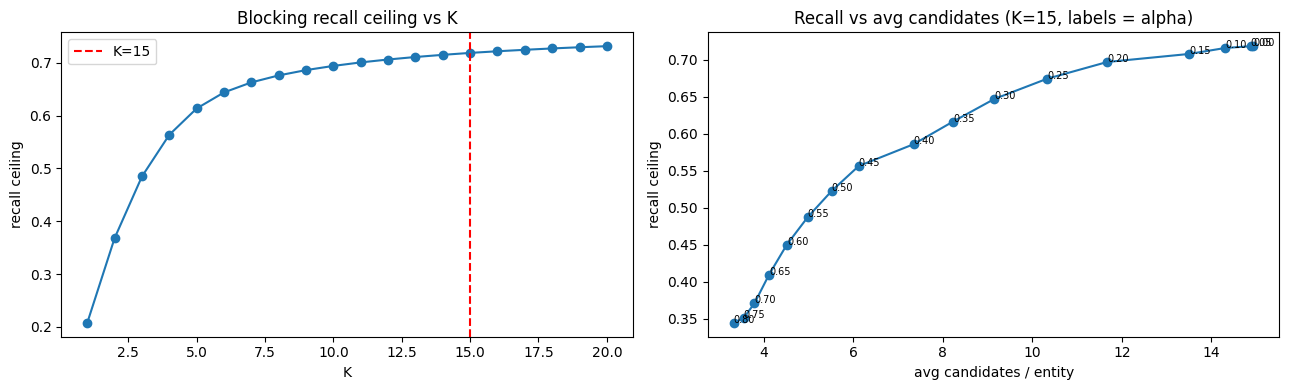

In [16]:
if RUN_TRAINING:
    TOP_K_CHOSEN, recall_df = P.choose_top_k(td, cfg)
    ALPHA, alpha_df = P.choose_alpha(td, TOP_K_CHOSEN, cfg)
    print(f"Chosen top-K = {TOP_K_CHOSEN}, alpha = {ALPHA}")
    display(recall_df.round(4).T)
    display(alpha_df.round(4).T)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(recall_df["k"], recall_df["recall_ceiling"], marker="o")
    ax[0].axvline(TOP_K_CHOSEN, color="red", ls="--", label=f"K={TOP_K_CHOSEN}")
    ax[0].set(title="Blocking recall ceiling vs K", xlabel="K", ylabel="recall ceiling"); ax[0].legend()
    ax[1].plot(alpha_df["avg_candidates"], alpha_df["recall_ceiling"], marker="o")
    for _, r in alpha_df.iterrows():
        ax[1].annotate(f"{r['alpha']:.2f}", (r["avg_candidates"], r["recall_ceiling"]), fontsize=7)
    ax[1].set(title=f"Recall vs avg candidates (K={TOP_K_CHOSEN}, labels = alpha)", xlabel="avg candidates / entity",
              ylabel="recall ceiling")
    plt.tight_layout(); plt.show()

## Step 3 — Train the matcher and tune the decision rule (validation = 20% of entities, grouped split)

Train pairs 3,570,093 | validation pairs 892,276 (60,000 validation entities, group split by Source-1 entity)
[250]	val's binary_logloss: 0.0300722
[500]	val's binary_logloss: 0.0270687
[750]	val's binary_logloss: 0.0258502
[1000]	val's binary_logloss: 0.025231
[1250]	val's binary_logloss: 0.0248975
[1500]	val's binary_logloss: 0.0246366
[1750]	val's binary_logloss: 0.0243949
[2000]	val's binary_logloss: 0.0242146
[2250]	val's binary_logloss: 0.0240855
[2500]	val's binary_logloss: 0.0239996
[2750]	val's binary_logloss: 0.0239079
[3000]	val's binary_logloss: 0.0238331
[3250]	val's binary_logloss: 0.0237955
[3500]	val's binary_logloss: 0.0237555
[3750]	val's binary_logloss: 0.0237158
[4000]	val's binary_logloss: 0.0236724
Model trained: 3997 boosting rounds (853s)
            VALIDATION SCORECARD (realistic full-pool blocking)
  Macro F0.5 (official metric)      : 0.8206
  Macro precision / recall          : 0.8916 / 0.7048
  Singleton accuracy                : 0.9218  (n=3300)
  Matched

,entities,macro_f05,singleton_rate,predicted_empty_rate
country,,,,
India,23921,0.7467,0.0543,0.2081
US,36079,0.8696,0.0554,0.0992


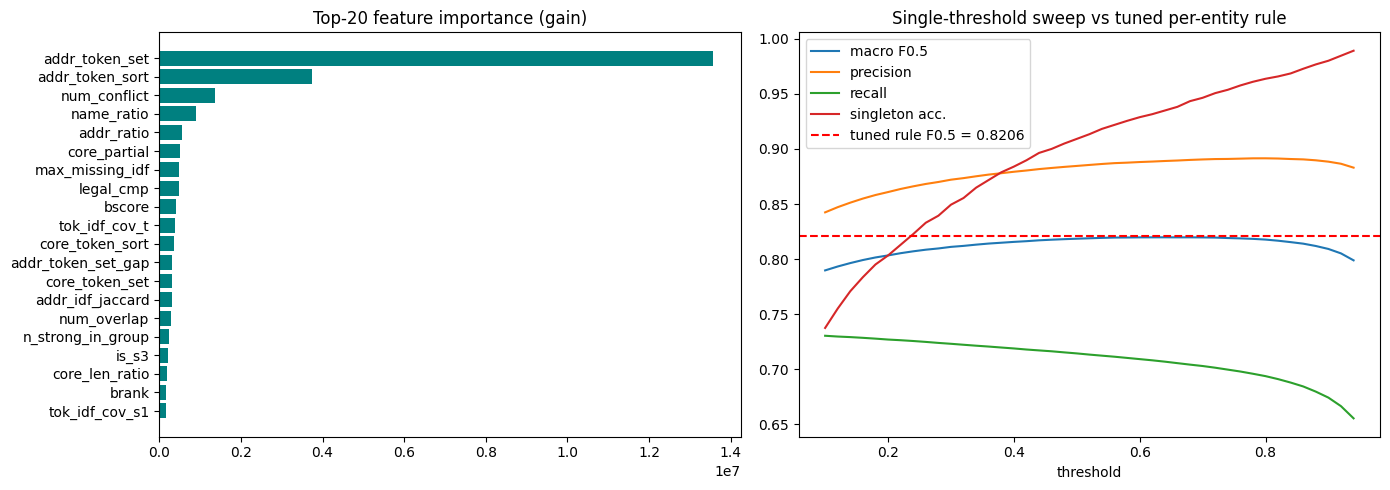

In [17]:
if RUN_TRAINING:
    result = P.train_and_tune(td, TOP_K_CHOSEN, ALPHA, cfg)
    P.save_artifacts(cfg, result)
else:
    result = P.load_result(cfg)
    print("Loaded saved model and rule from", ARTIFACTS_DIR)

m, rule, single = result["metrics"], result["rule"], result["best_single_threshold"]
print("=" * 78)
print("            VALIDATION SCORECARD (realistic full-pool blocking)")
print("=" * 78)
print(f"  Macro F0.5 (official metric)      : {m['macro_f05']:.4f}")
print(f"  Macro precision / recall          : {m['macro_precision']:.4f} / {m['macro_recall']:.4f}")
print(f"  Singleton accuracy                : {m['singleton_accuracy']:.4f}  (n={m['singleton_count']})")
print(f"  Matched-entity F0.5               : {m['matched_entity_f05']:.4f}")
print(f"  Blocking recall ceiling           : {m['blocking_recall_ceiling']:.4f}")
print(f"  Avg candidates / entity           : {m['avg_candidates']:.2f}  (top-K={result['top_k']}, alpha={result['alpha']})")
print(f"  Decision rule                     : {rule}")
print(f"  Best single threshold (V2 rule)   : {single['macro_f05']:.4f} at tau={single['threshold']}")
print(f"  GT targets with >1 Source-1 match : {m['gt_target_multi_rate']:.4%} -> target exclusivity "
      f"{'ON' if result['exclusive'] else 'OFF'} (val F0.5 with it: {m['macro_f05_with_exclusivity_on_val']:.4f})")
print("=" * 78)
display(result["per_country"].round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp = result["importance"].head(20)[::-1]
ax[0].barh(imp["feature"], imp["gain"], color="teal"); ax[0].set_title("Top-20 feature importance (gain)")
c = result["single_threshold_curve"]
for col, lab in (("macro_f05", "macro F0.5"), ("macro_precision", "precision"), ("macro_recall", "recall"),
                 ("singleton_accuracy", "singleton acc.")):
    ax[1].plot(c["threshold"], c[col], label=lab)
ax[1].axhline(m["macro_f05"], color="red", ls="--", label=f"tuned rule F0.5 = {m['macro_f05']:.4f}")
ax[1].set(title="Single-threshold sweep vs tuned per-entity rule", xlabel="threshold"); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 4 — Streaming test inference (all countries, France zero-shot)
Writes `output/candidate_pairs.tsv` (exactly the pairs the model scores) and `output/matching_results.tsv`.
Progress lines show throughput, ETA and the running non-empty-prediction rate per country.

In [18]:
if RUN_TRAINING:
    del td
    gc.collect()
test_summary = P.run_test_inference(cfg, result["model"], result["top_k"], result["rule"], result["alpha"],
                                    result["exclusive"])
test_summary.to_csv(ARTIFACTS_DIR / "test_summary.csv", index=False)
display(test_summary.round(4))

Test: 1,732,544 Source-1 entities {'India': 809986, 'US': 663106, 'France': 259452} | 9,969,589 target records {'India': 4717565, 'US': 3817031, 'France': 1434993}
top_k=15 alpha=0.05 rule={'gate': 0.56, 'pair': 0.5, 'rel': 0.7} target_exclusivity=True
[France] target pool ready: 1,434,993 records, 1,842,040 blocking keys (67s)
[France] 20,000/259,452 entities | 322/s | ETA 12.4 min | selected pairs 52,186
[France] 40,000/259,452 entities | 321/s | ETA 11.4 min | selected pairs 104,466
[France] 60,000/259,452 entities | 320/s | ETA 10.4 min | selected pairs 156,773
[France] 80,000/259,452 entities | 320/s | ETA 9.3 min | selected pairs 209,670
[France] 100,000/259,452 entities | 318/s | ETA 8.4 min | selected pairs 262,046
[France] 120,000/259,452 entities | 319/s | ETA 7.3 min | selected pairs 314,661
[France] 140,000/259,452 entities | 319/s | ETA 6.2 min | selected pairs 367,352
[France] 160,000/259,452 entities | 319/s | ETA 5.2 min | selected pairs 419,970
[France] 180,000/259,452

,country,s1_entities,avg_candidates,non_empty_match_rate,avg_matches_when_non_empty,exclusivity_removed
0,France,259452,14.8307,0.8660,2.9163,26014
1,India,809986,14.9199,0.7872,2.7502,5910
2,US,663106,14.9056,0.9143,2.9588,2927


## Step 5 — Validate the submission files
Checks every rule (one row per Source-1 test entity, S2/S3 ids that exist in the test set, no duplicates,
matches ⊆ candidates) and then runs the organisers' `utils/validate_submission.py` if it is in the dataset.

In [19]:
ok = V.validate_outputs(OUTPUT_DIR, TEST_DIR)
V.run_official_validator(OUTPUT_DIR, TEST_DIR)
assert ok, "Submission files failed validation - see messages above."

matching_results.tsv : 1,732,544 rows | non-empty 1,468,563 (84.8%) | avg matches 2.43
candidate_pairs.tsv  : 1,732,544 rows | avg candidates / Source-1 entity 14.90
VALIDATION PASSED: all challenge format rules satisfied.
ML Challenge 2026 — submission validator
  test dir: /kaggle/input/datasets/nikhileshj/nikhil-dataset/student_resource/dataset/test
  required S1 entities: 1732544
  matching_results.tsv: 1732544 rows (263981 empty, 1468563 non-empty).
  candidate_pairs.tsv: 1732544 rows (386 empty, 1732158 non-empty).

PASS — no blocking issues found. Safe to submit.

Official validator exit code: 0 (PASS)


## Step 6 — Methodology document + final submission zip

In [20]:
methodology = PK.methodology_markdown(TEAM_NAME, result, test_summary)
(WORK_DIR / "Documentation_template.md").write_text(methodology, encoding="utf-8")
zip_path = PK.build_submission_zip(TEAM_NAME, WORK_DIR, OUTPUT_DIR, SRC_DIR, methodology)
print(f"Submission package: {zip_path}  ({zip_path.stat().st_size / 1e6:.1f} MB)")
print(f"Leaderboard file  : {OUTPUT_DIR / 'matching_results.tsv'}")
import zipfile
for n in zipfile.ZipFile(zip_path).namelist():
    print("  ", n)

Submission package: /kaggle/working/Amritians_submission.zip  (183.1 MB)
Leaderboard file  : /kaggle/working/output/matching_results.tsv
   output/matching_results.tsv
   output/candidate_pairs.tsv
   code/business_entity_resolution/src/er/__init__.py
   code/business_entity_resolution/src/er/blocking.py
   code/business_entity_resolution/src/er/data.py
   code/business_entity_resolution/src/er/decision.py
   code/business_entity_resolution/src/er/features.py
   code/business_entity_resolution/src/er/model.py
   code/business_entity_resolution/src/er/package.py
   code/business_entity_resolution/src/er/pipeline.py
   code/business_entity_resolution/src/er/preprocess.py
   code/business_entity_resolution/src/er/validate.py
   code/business_entity_resolution/src/run_pipeline.py
   code/business_entity_resolution/README.md
   code/business_entity_resolution/requirements.txt
   Documentation_template.md
